# Abalone Age Prediction
Compare 3 models (Linear Regression, Decision Tree, Random Forest), then refine the best one.

**Age = Rings + 1.5**, so predicting Rings is the same as predicting age.

In [4]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

## 1. Load the data

In [5]:
# reading the data  (abalone.csv must be in the same folder as this notebook;
# in Colab, upload it or change the path to your Drive location)

data = pd.read_csv('abalone.csv')

# getting the shape
data.shape

(4177, 9)

In [6]:
# looking at the head of the data

data.head()

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [7]:
# describe the data

data.describe()

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
count,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000,4177.000000
mean,0.523992,0.407881,0.139516,0.828742,0.359367,0.180594,0.238831,9.933684
std,0.120093,0.099240,0.041827,0.490389,0.221963,0.109614,0.139203,3.224169
min,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,0.450000,0.350000,0.115000,0.441500,0.186000,0.093500,0.130000,8.000000
50%,0.545000,0.425000,0.140000,0.799500,0.336000,0.171000,0.234000,9.000000
75%,0.615000,0.480000,0.165000,1.153000,0.502000,0.253000,0.329000,11.000000
max,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


In [8]:
# information of the data

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4177 entries, 0 to 4176
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sex             4177 non-null   object 
 1   Length          4177 non-null   float64
 2   Diameter        4177 non-null   float64
 3   Height          4177 non-null   float64
 4   Whole weight    4177 non-null   float64
 5   Shucked weight  4177 non-null   float64
 6   Viscera weight  4177 non-null   float64
 7   Shell weight    4177 non-null   float64
 8   Rings           4177 non-null   int64  
dtypes: float64(7), int64(1), object(1)
memory usage: 293.8+ KB


In [9]:
# checking if there is any NULL data

data.isnull().sum()

,0
Sex,0
Length,0
Diameter,0
Height,0
Whole weight,0
Shucked weight,0
Viscera weight,0
Shell weight,0
Rings,0


## 2. Clean the data

In [10]:
# Height = 0 is physically impossible, so those rows are invalid

print("Rows with Height = 0:", (data['Height'] == 0).sum())
data = data[data['Height'] > 0].reset_index(drop = True)
data.shape

Rows with Height = 0: 2


(4175, 9)

## 3. Exploratory data analysis

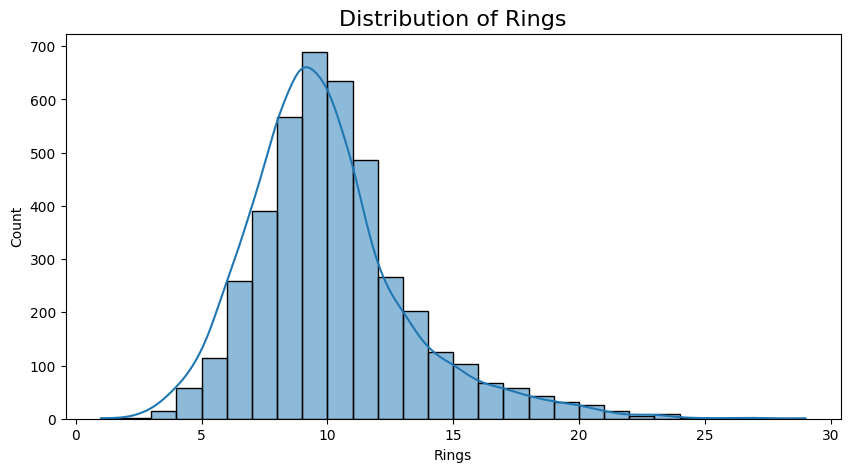

In [11]:
# distribution of the target

plt.rcParams['figure.figsize'] = (10, 5)
sns.histplot(data['Rings'], bins = 28, kde = True)
plt.title('Distribution of Rings', fontsize = 16)
plt.show()

In [12]:
# checking the values of sex

data['Sex'].value_counts()

,count
Sex,
M,1528
I,1340
F,1307


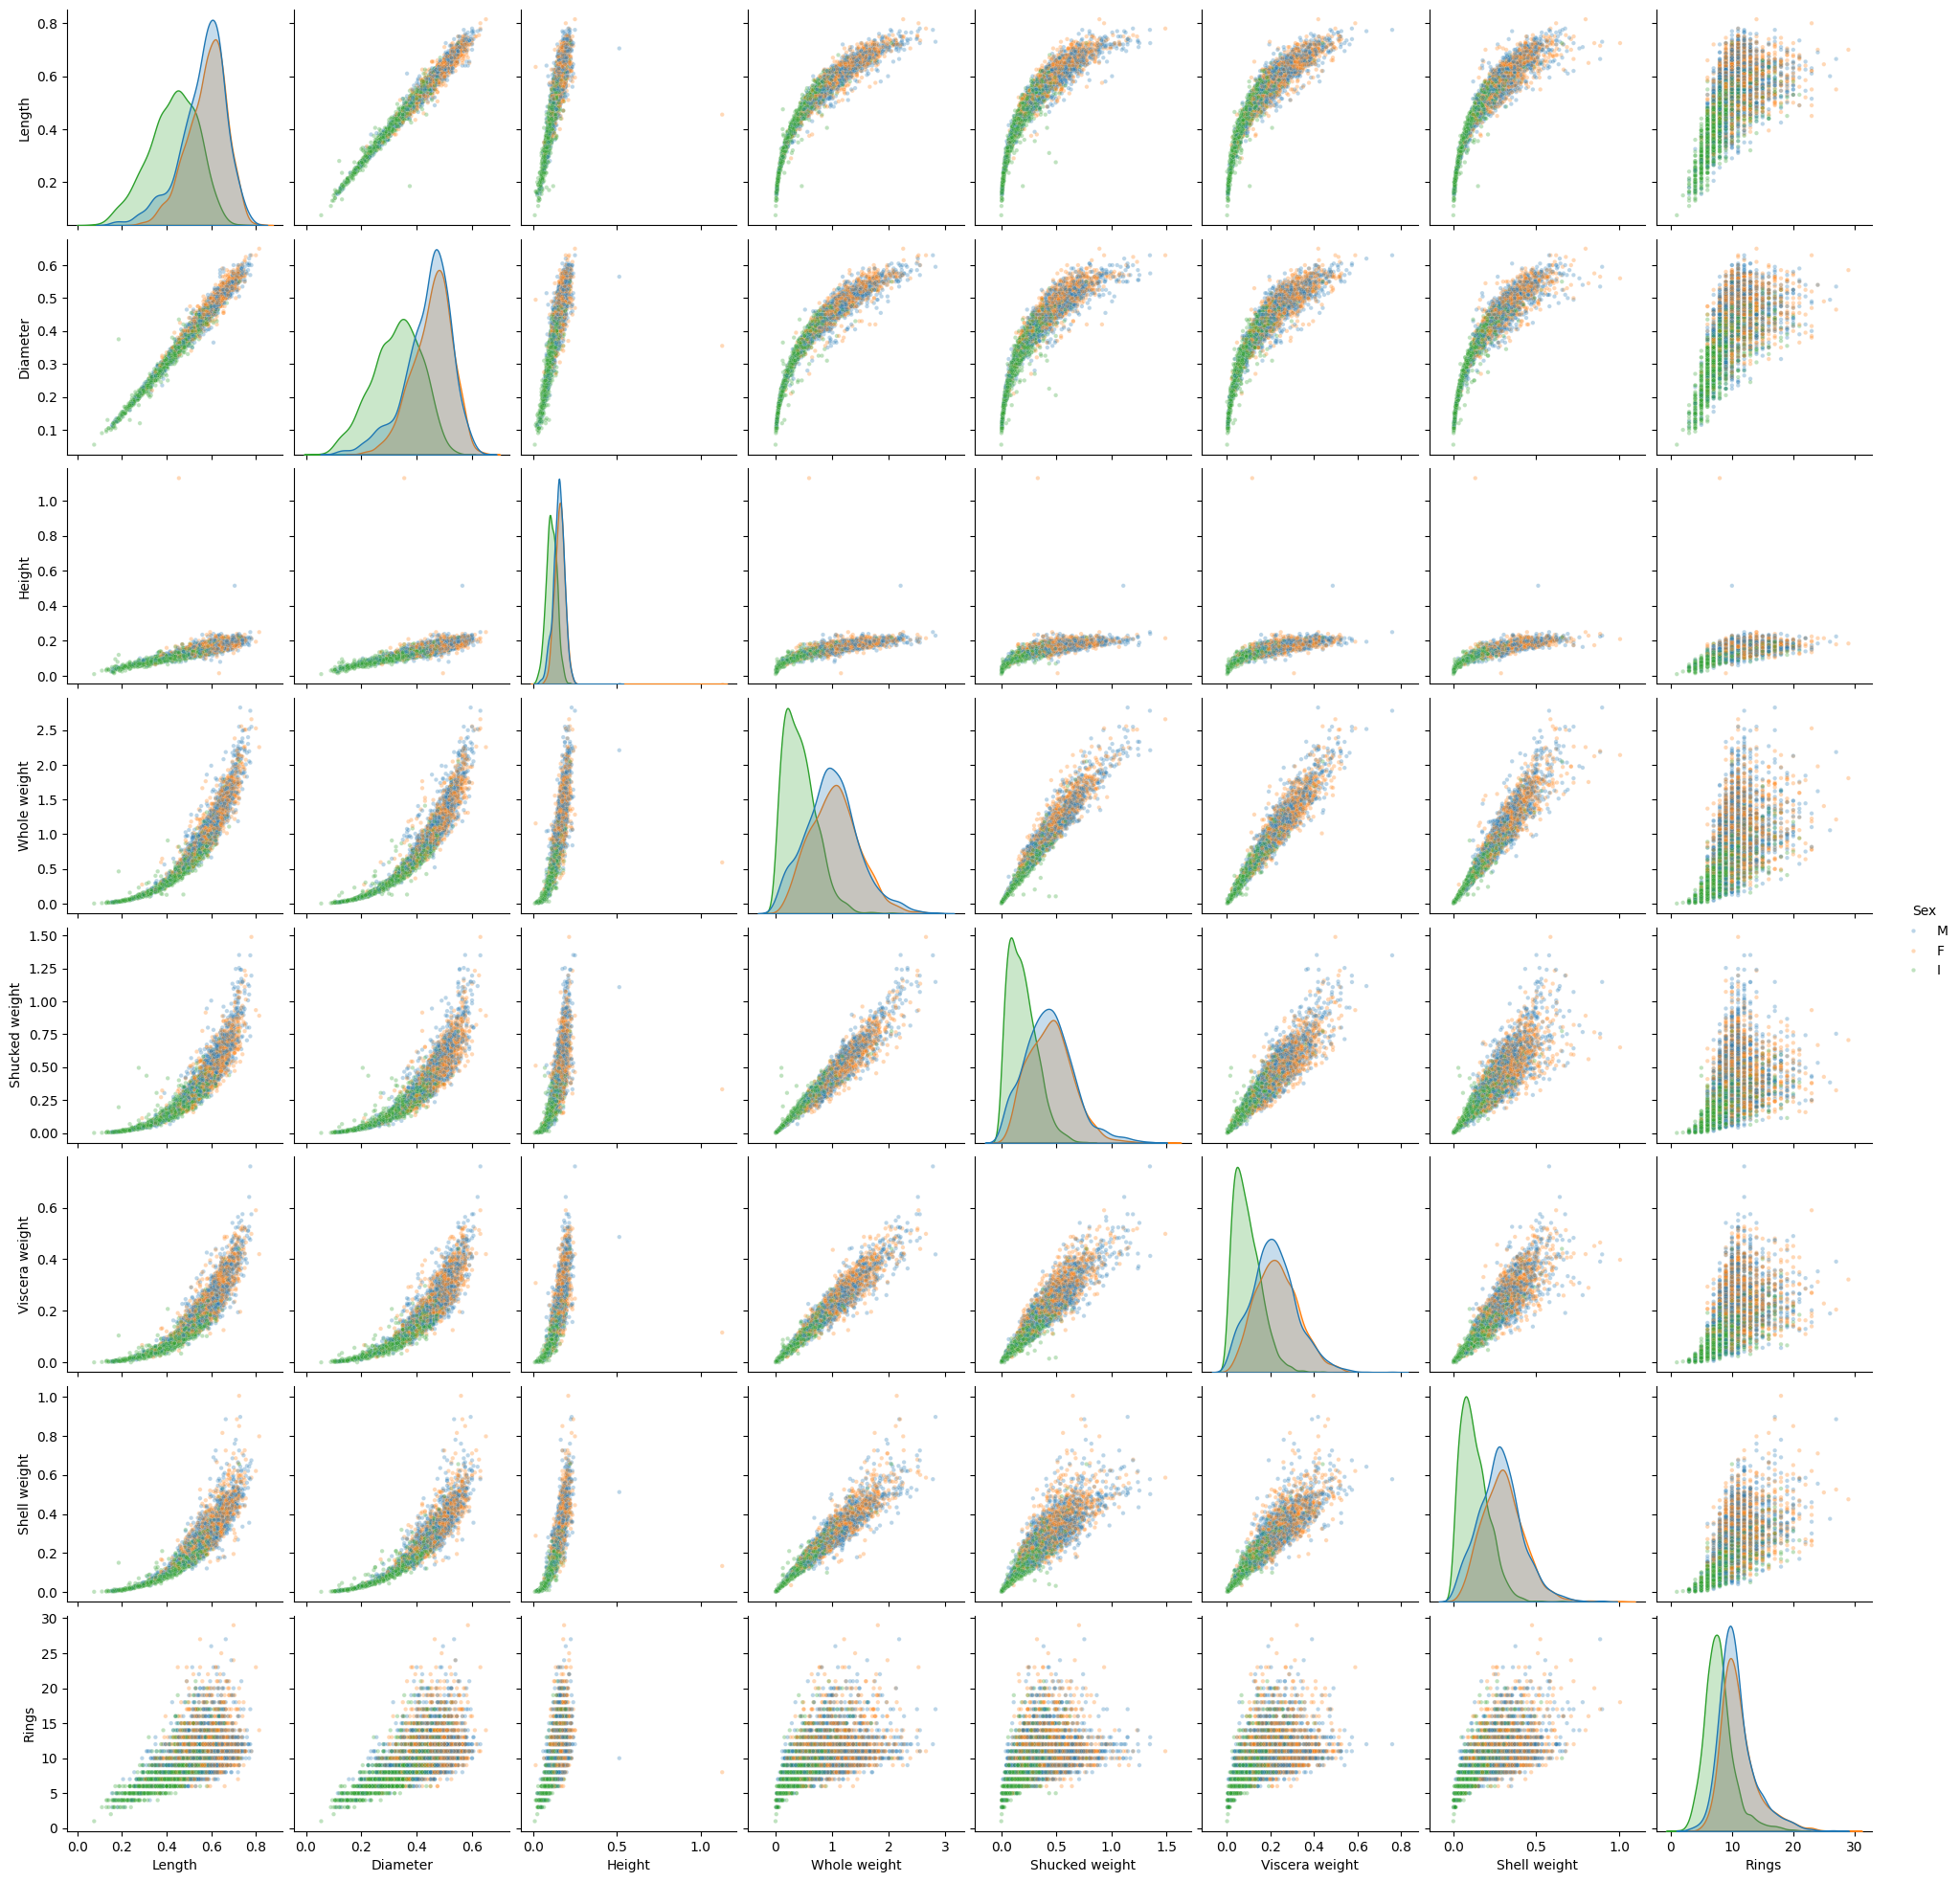

In [13]:
# pairplot

sns.pairplot(data, hue = 'Sex', plot_kws = {'alpha': 0.3, 's': 10})
plt.show()

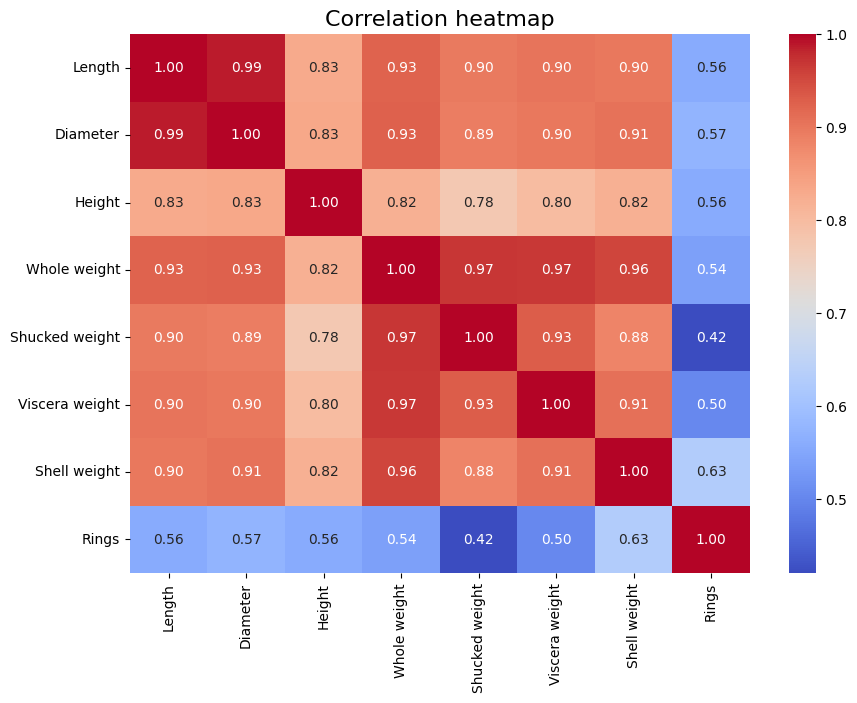

In [14]:
# correlation heatmap

plt.rcParams['figure.figsize'] = (10, 7)
sns.heatmap(data.drop('Sex', axis = 1).corr(), annot = True, cmap = 'coolwarm', fmt = '.2f')
plt.title('Correlation heatmap', fontsize = 16)
plt.show()

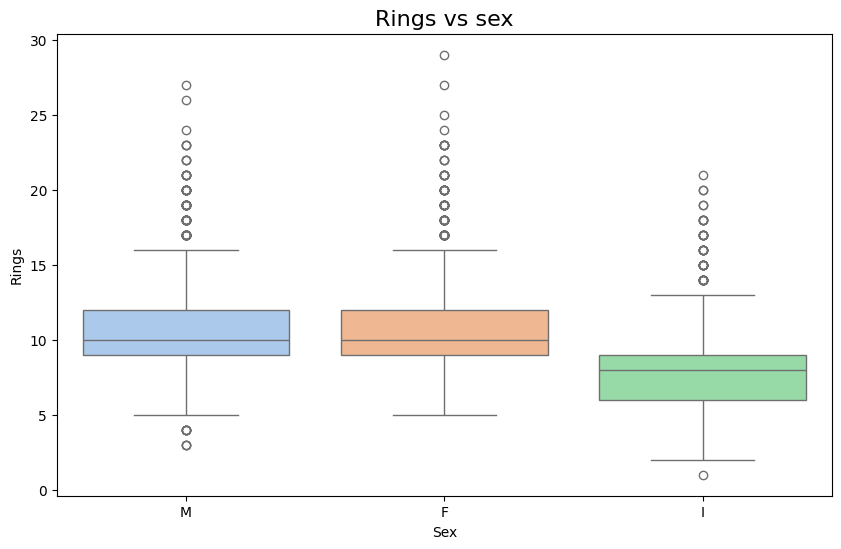

In [15]:
# rings vs sex

plt.rcParams['figure.figsize'] = (10, 6)
sns.boxplot(x = 'Sex', y = 'Rings', data = data, palette = 'pastel')
plt.title('Rings vs sex', fontsize = 16)
plt.show()

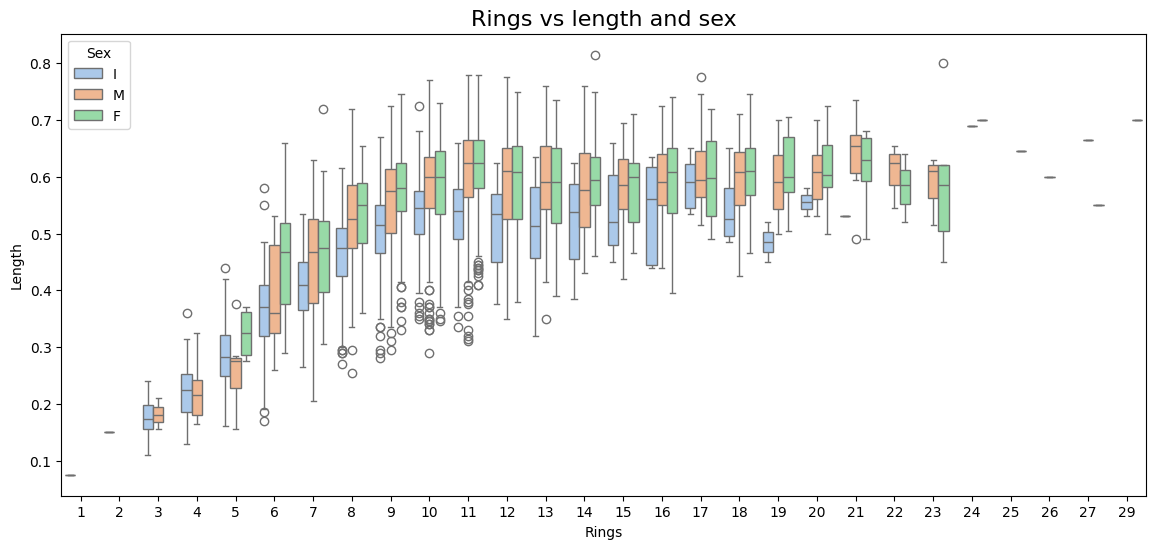

In [16]:
# rings vs length and sex

plt.rcParams['figure.figsize'] = (14, 6)
sns.boxplot(x = 'Rings', y = 'Length', hue = 'Sex', data = data, palette = 'pastel')
plt.title('Rings vs length and sex', fontsize = 16)
plt.show()

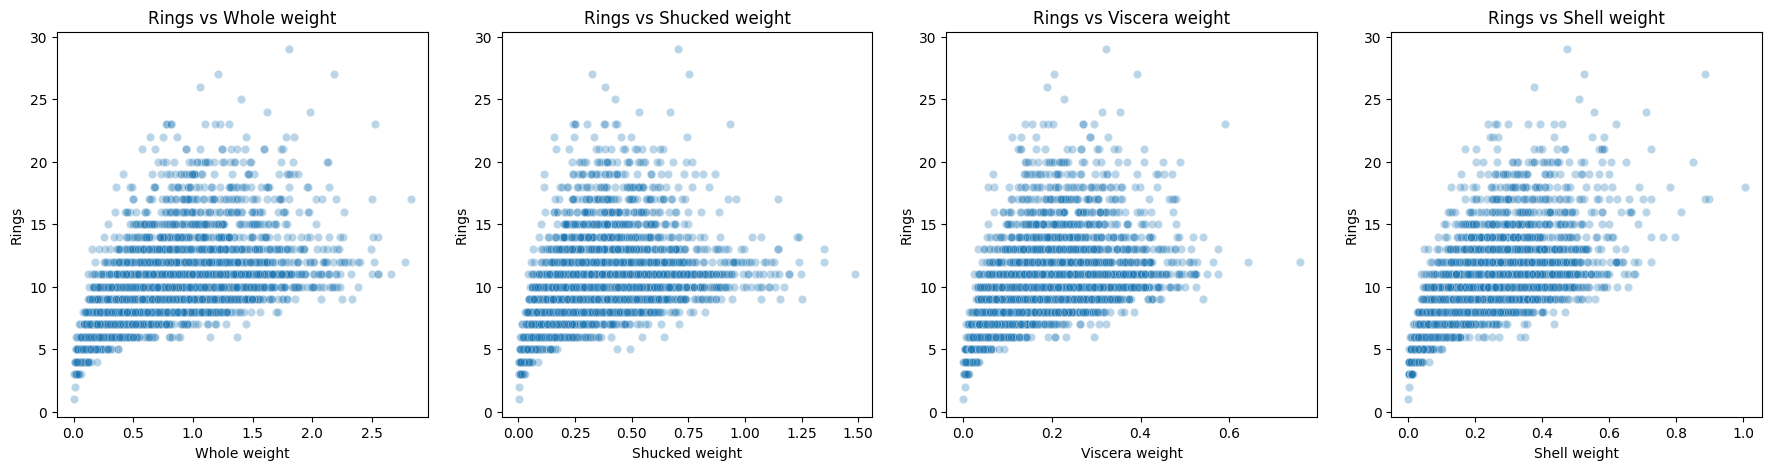

In [17]:
# rings vs weights

fig, axes = plt.subplots(1, 4, figsize = (22, 5))
for ax, col in zip(axes, ['Whole weight', 'Shucked weight', 'Viscera weight', 'Shell weight']):
    sns.scatterplot(x = col, y = 'Rings', data = data, alpha = 0.3, ax = ax)
    ax.set_title('Rings vs ' + col)
plt.show()

## 4. Prepare the data

In [18]:
# one-hot encoding the Sex column

data = pd.get_dummies(data, columns = ['Sex'])
data.head()

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings,Sex_F,Sex_I,Sex_M
0,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15,False,False,True
1,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7,False,False,True
2,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9,True,False,False
3,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10,False,False,True
4,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7,False,True,False


In [19]:
# splitting the dependent and independent variables

y = data['Rings']
x = data.drop(['Rings'], axis = 1)

# getting the shapes
print("Shape of x:", x.shape)
print("Shape of y:", y.shape)

Shape of x: (4175, 10)
Shape of y: (4175,)


In [20]:
# train test split

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 0)

# getting the shapes
print("Shape of x_train :", x_train.shape)
print("Shape of x_test :", x_test.shape)

Shape of x_train : (3340, 10)
Shape of x_test : (835, 10)


## 5. Modelling: compare 3 models

In [21]:
# helper to evaluate any model the same way

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score, KFold

kf = KFold(n_splits = 5, shuffle = True, random_state = 0)
results = []

def evaluate(model, name, xtr = x_train, xte = x_test):
    model.fit(xtr, y_train)
    y_pred = model.predict(xte)
    cv_rmse = -cross_val_score(model, xtr, y_train, cv = kf,
                               scoring = 'neg_root_mean_squared_error').mean()
    res = {'Model': name,
           'MAE': mean_absolute_error(y_test, y_pred),
           'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
           'R2': r2_score(y_test, y_pred),
           'CV RMSE': cv_rmse}
    results.append(res)
    print(name, {k: round(float(v), 3) for k, v in res.items() if k != 'Model'})
    return y_pred

In [22]:
# MODEL 1: LINEAR REGRESSION

from sklearn.linear_model import LinearRegression

lr = LinearRegression()
pred_lr = evaluate(lr, 'Linear Regression')

Linear Regression {'MAE': 1.581, 'RMSE': 2.223, 'R2': 0.502, 'CV RMSE': 2.211}


In [23]:
# MODEL 2: DECISION TREE REGRESSOR (default settings, fully grown)

from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(random_state = 0)
pred_dt = evaluate(dt, 'Decision Tree')

Decision Tree {'MAE': 2.071, 'RMSE': 3.005, 'R2': 0.09, 'CV RMSE': 2.92}


In [24]:
# MODEL 3: RANDOM FOREST REGRESSOR

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators = 100, random_state = 0, n_jobs = -1)
pred_rf = evaluate(rf, 'Random Forest')

Random Forest {'MAE': 1.546, 'RMSE': 2.167, 'R2': 0.527, 'CV RMSE': 2.197}


In [25]:
# comparison table

comparison = pd.DataFrame(results).set_index('Model').round(3)
comparison

,MAE,RMSE,R2,CV RMSE
Model,,,,
Linear Regression,1.581,2.223,0.502,2.211
Decision Tree,2.071,3.005,0.090,2.920
Random Forest,1.546,2.167,0.527,2.197


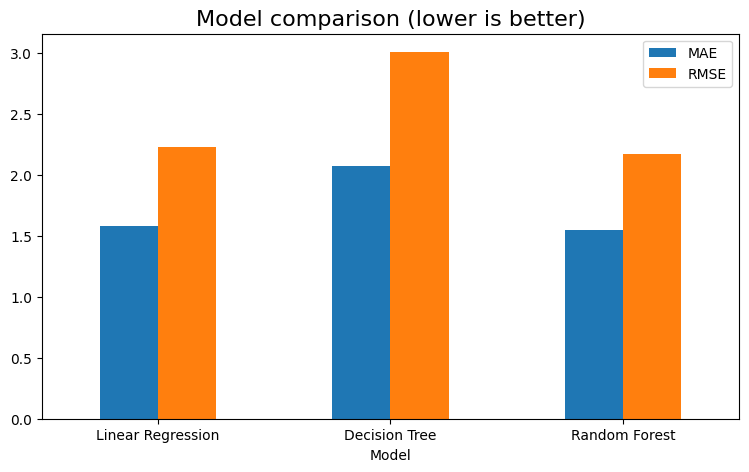

In [26]:
# comparison plot

comparison[['MAE', 'RMSE']].plot(kind = 'bar', figsize = (9, 5), rot = 0)
plt.title('Model comparison (lower is better)', fontsize = 16)
plt.show()

## 6. Refinement
The fully grown decision tree overfits (it memorises the training data), so we first prune it with tuning. Then we refine the Random Forest and the features.

In [27]:
# REFINEMENT 1: TUNE THE DECISION TREE (limit depth and leaf size)

from sklearn.model_selection import GridSearchCV

dt_grid = {'max_depth': [3, 4, 5, 6, 8, 10],
           'min_samples_leaf': [5, 10, 20, 40],
           'min_samples_split': [2, 10, 20]}

dt_gs = GridSearchCV(DecisionTreeRegressor(random_state = 0), dt_grid, cv = kf,
                     scoring = 'neg_root_mean_squared_error', n_jobs = -1).fit(x_train, y_train)

print("Best params:", dt_gs.best_params_)
pred_dt_tuned = evaluate(dt_gs.best_estimator_, 'Decision Tree (tuned)')

Best params: {'max_depth': 10, 'min_samples_leaf': 40, 'min_samples_split': 2}
Decision Tree (tuned) {'MAE': 1.63, 'RMSE': 2.303, 'R2': 0.466, 'CV RMSE': 2.277}


In [28]:
# REFINEMENT 2: FEATURE ENGINEERING
# weights and sizes are highly correlated, so ratios give the models new information

def add_features(d):
    d = d.copy()
    d['Volume'] = d['Length'] * d['Diameter'] * d['Height']
    d['Shell ratio'] = d['Shell weight'] / d['Whole weight']
    d['Shucked ratio'] = d['Shucked weight'] / d['Whole weight']
    d['Viscera ratio'] = d['Viscera weight'] / d['Whole weight']
    return d

xf_train, xf_test = add_features(x_train), add_features(x_test)
xf_train.head()

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Sex_F,Sex_I,Sex_M,Volume,Shell ratio,Shucked ratio,Viscera ratio
188,0.630,0.480,0.160,1.1990,0.5265,0.3350,0.315,True,False,False,0.048384,0.262719,0.439116,0.279399
2324,0.415,0.305,0.105,0.3605,0.1200,0.0820,0.100,True,False,False,0.013290,0.277393,0.332871,0.227462
219,0.415,0.305,0.130,0.3200,0.1305,0.0755,0.105,True,False,False,0.016455,0.328125,0.407813,0.235937
380,0.605,0.470,0.180,1.1405,0.3755,0.2805,0.385,False,False,True,0.051183,0.337571,0.329242,0.245945
218,0.470,0.360,0.135,0.5010,0.1665,0.1150,0.165,False,False,True,0.022842,0.329341,0.332335,0.229541


In [29]:
# REFINEMENT 3: TUNE THE RANDOM FOREST on the engineered features

from sklearn.model_selection import RandomizedSearchCV

rf_grid = {'n_estimators': [200, 300, 500],
           'max_depth': [6, 8, 10, 12, None],
           'min_samples_leaf': [1, 3, 5, 10],
           'max_features': ['sqrt', 0.5, 1.0]}

rf_gs = RandomizedSearchCV(RandomForestRegressor(random_state = 0, n_jobs = -1), rf_grid,
                           n_iter = 15, cv = kf, scoring = 'neg_root_mean_squared_error',
                           random_state = 0).fit(xf_train, y_train)

print("Best params:", rf_gs.best_params_)
best_rf = rf_gs.best_estimator_
pred_best = evaluate(best_rf, 'Random Forest (tuned + features)', xf_train, xf_test)

Best params: {'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': None}
Random Forest (tuned + features) {'MAE': 1.452, 'RMSE': 2.082, 'R2': 0.563, 'CV RMSE': 2.093}


In [30]:
# final comparison

final = pd.DataFrame(results).set_index('Model').round(3)
final.sort_values('RMSE')

,MAE,RMSE,R2,CV RMSE
Model,,,,
Random Forest (tuned + features),1.452,2.082,0.563,2.093
Random Forest,1.546,2.167,0.527,2.197
Linear Regression,1.581,2.223,0.502,2.211
Decision Tree (tuned),1.630,2.303,0.466,2.277
Decision Tree,2.071,3.005,0.090,2.920


## 7. Final model analysis

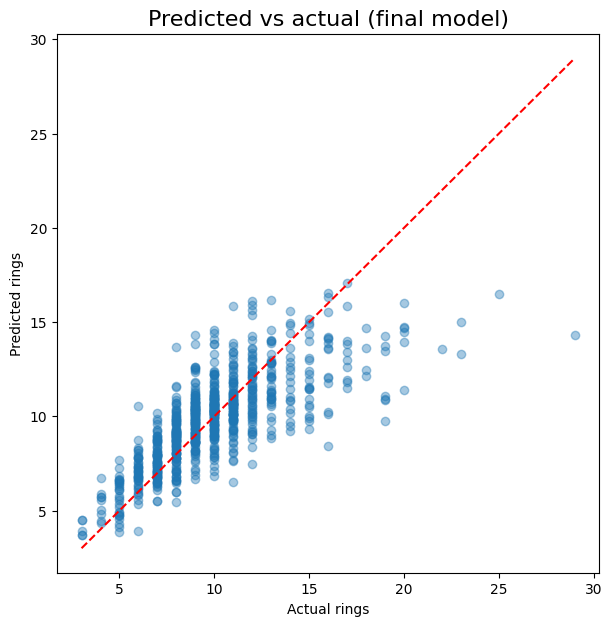

Within +-1 ring : 0.484
Within +-2 rings: 0.78


In [31]:
# predicted vs actual

plt.rcParams['figure.figsize'] = (7, 7)
plt.scatter(y_test, pred_best, alpha = 0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual rings')
plt.ylabel('Predicted rings')
plt.title('Predicted vs actual (final model)', fontsize = 16)
plt.show()

print("Within +-1 ring :", round(np.mean(np.abs(pred_best - y_test) <= 1), 3))
print("Within +-2 rings:", round(np.mean(np.abs(pred_best - y_test) <= 2), 3))

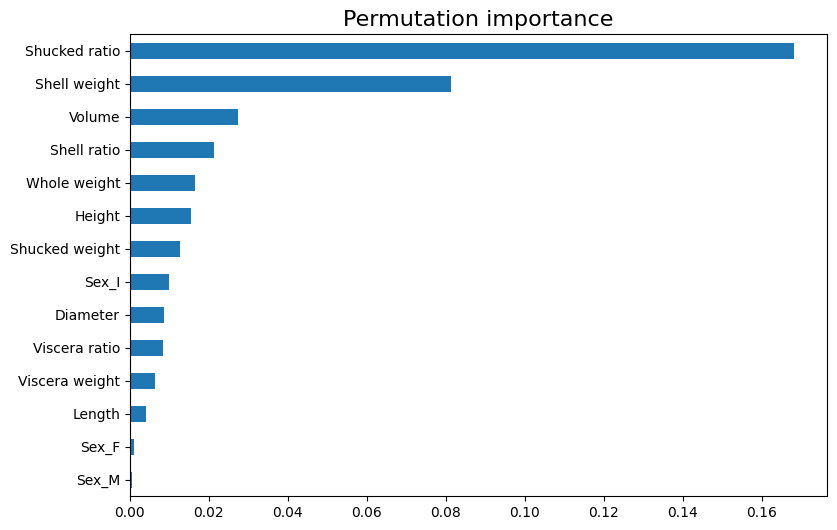

In [32]:
# let's check the importance of each attribute (permutation importance)

from sklearn.inspection import permutation_importance

perm = permutation_importance(best_rf, xf_test, y_test, n_repeats = 10, random_state = 0)
imp = pd.Series(perm.importances_mean, index = xf_test.columns).sort_values()

plt.rcParams['figure.figsize'] = (9, 6)
imp.plot(kind = 'barh')
plt.title('Permutation importance', fontsize = 16)
plt.show()

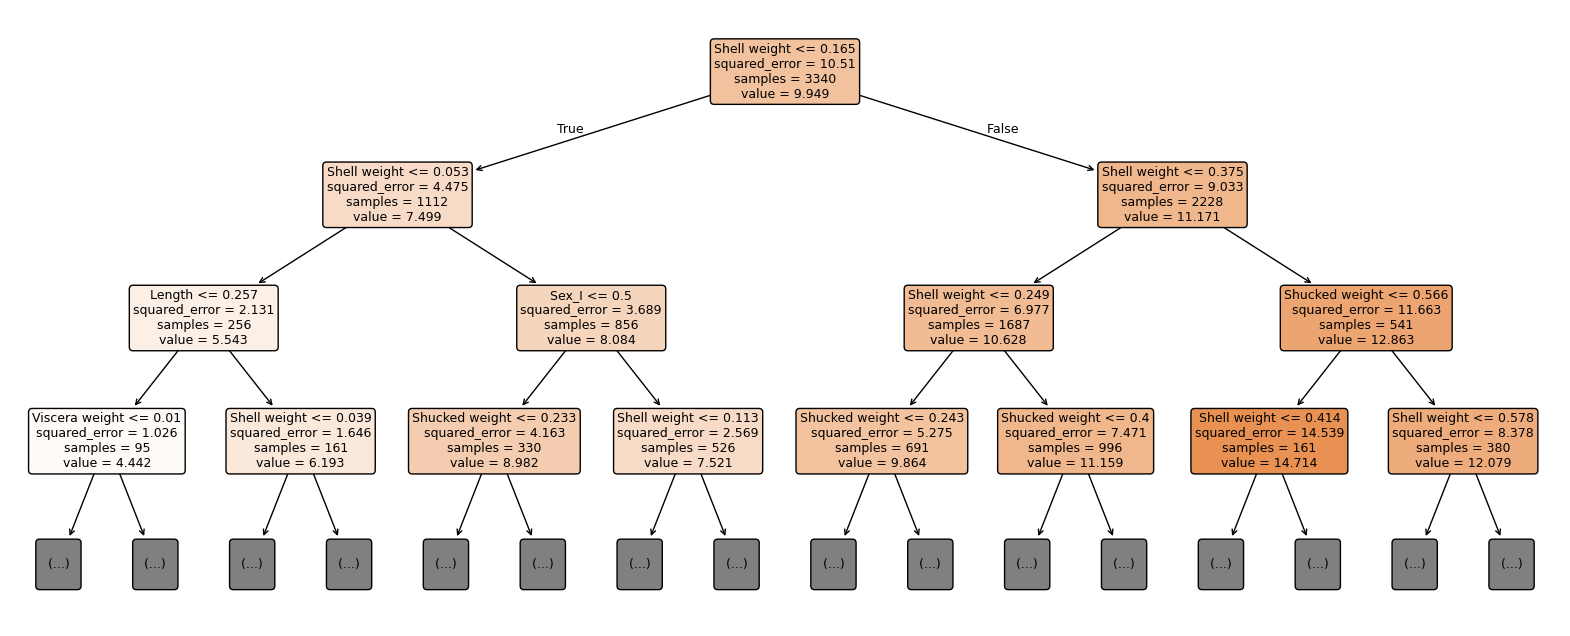

In [33]:
# visualising the tuned decision tree (top 3 levels)

from sklearn.tree import plot_tree

plt.figure(figsize = (20, 8))
plot_tree(dt_gs.best_estimator_, feature_names = x_train.columns, max_depth = 3,
          filled = True, rounded = True, fontsize = 9)
plt.show()

## 8. Conclusion
_Write your findings here: which model won, how much refinement helped, which features mattered most, and why R² is limited (abalone age is hard to read from external measurements alone)._